In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.feature import canny

if not os.path.exists('input.jpg'):
    cv2.imwrite('input.jpg', data.camera())

img = cv2.imread('input.jpg', cv2.IMREAD_GRAYSCALE)

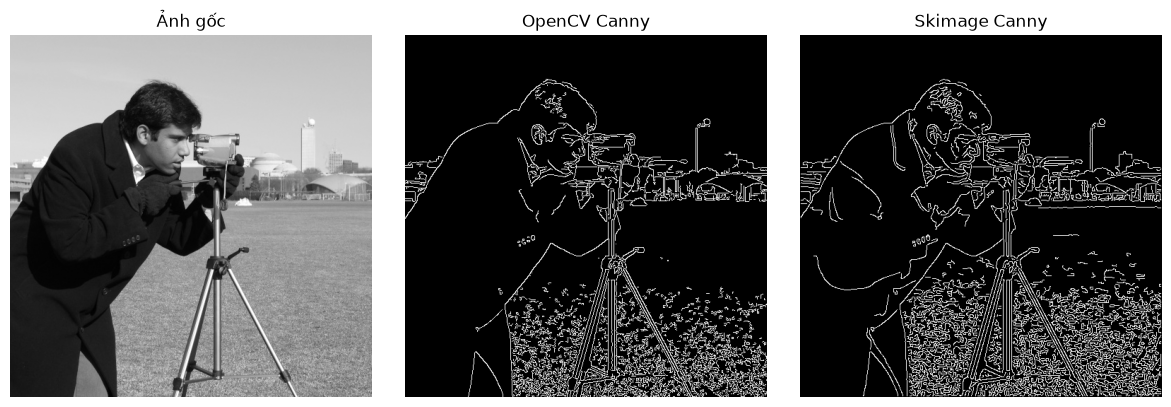

In [2]:
edges_cv = cv2.Canny(img, 100, 200)
edges_sk = canny(img)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Ảnh gốc', 'OpenCV Canny', 'Skimage Canny']
imgs = [img, edges_cv, edges_sk]

for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

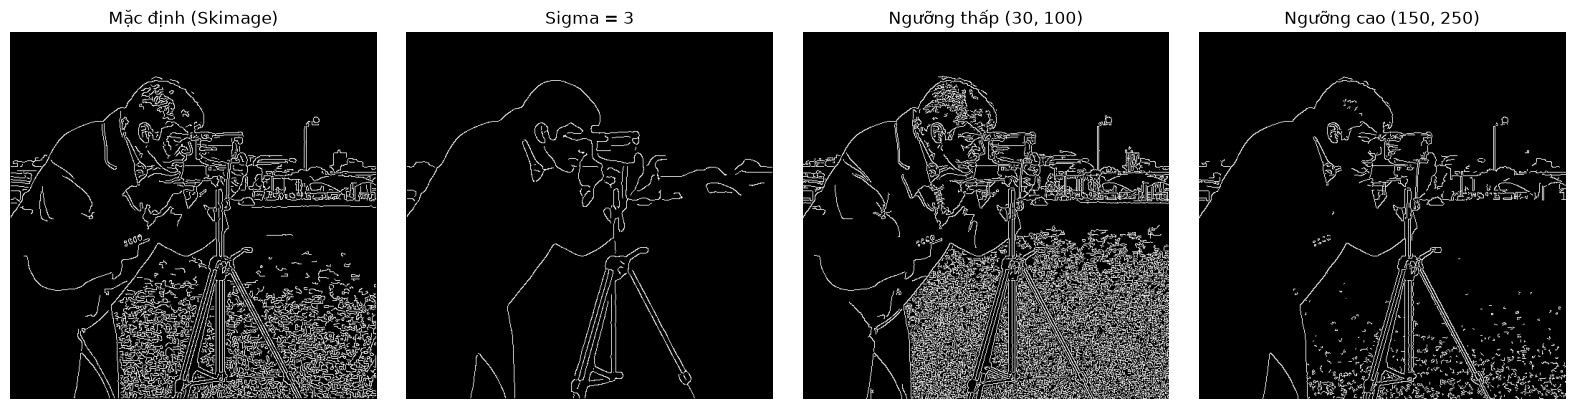

In [3]:
c_default = canny(img)
c_sigma3 = canny(img, sigma=3)
c_thresh_low = cv2.Canny(img, 30, 100)
c_thresh_high = cv2.Canny(img, 150, 250)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Mặc định (Skimage)', 'Sigma = 3', 'Ngưỡng thấp (30, 100)', 'Ngưỡng cao (150, 250)']
imgs = [c_default, c_sigma3, c_thresh_low, c_thresh_high]

for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

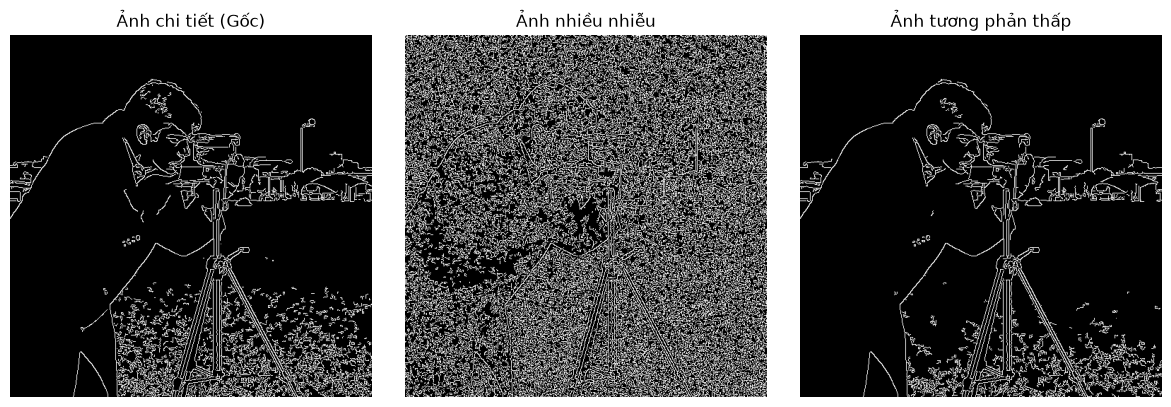

1. Ảnh nhiều chi tiết: Canny nhận diện biên rõ nét, chi tiết tách bạch.
2. Ảnh nhiều nhiễu: Xuất hiện nhiều cạnh giả do nhiễu, cần tăng sigma để lọc.
3. Ảnh tương phản thấp: Cạnh mờ nhạt và đứt đoạn, cần hạ thấp ngưỡng phát hiện.


In [4]:
noise = np.random.normal(0, 25, img.shape)
img_noisy = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
img_low_contrast = np.clip(img * 0.3 + 50, 0, 255).astype(np.uint8)

edge_detail = cv2.Canny(img, 100, 200)
edge_noisy = cv2.Canny(img_noisy, 100, 200)
edge_low = cv2.Canny(img_low_contrast, 30, 80)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Ảnh chi tiết (Gốc)', 'Ảnh nhiều nhiễu', 'Ảnh tương phản thấp']
imgs = [edge_detail, edge_noisy, edge_low]

for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

print('1. Ảnh nhiều chi tiết: Canny nhận diện biên rõ nét, chi tiết tách bạch.')
print('2. Ảnh nhiều nhiễu: Xuất hiện nhiều cạnh giả do nhiễu, cần tăng sigma để lọc.')
print('3. Ảnh tương phản thấp: Cạnh mờ nhạt và đứt đoạn, cần hạ thấp ngưỡng phát hiện.')

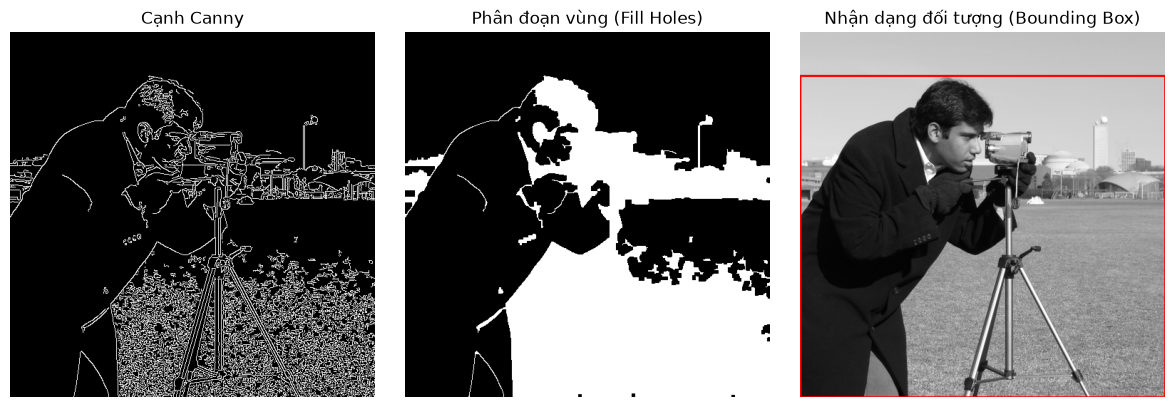

In [5]:
from scipy.ndimage import binary_fill_holes

edges = cv2.Canny(img, 50, 150)
kernel = np.ones((5, 5), np.uint8)
closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
segmented = binary_fill_holes(closed_edges)

contours, _ = cv2.findContours(closed_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_box = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

for cnt in contours:
    if cv2.contourArea(cnt) > 500:
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(img_box, (x, y), (x + w, y + h), (255, 0, 0), 2)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Cạnh Canny', 'Phân đoạn vùng (Fill Holes)', 'Nhận dạng đối tượng (Bounding Box)']
imgs = [edges, segmented, img_box]

for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im, cmap='gray' if len(im.shape) == 2 else None)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()